In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/refs/heads/master/titanic.csv")

In [ ]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# Operaciones fila

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# Expresiones regulares
df['title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

<>:2: SyntaxWarning: invalid escape sequence '\.'
<>:2: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_26906/3823569683.py:2: SyntaxWarning: invalid escape sequence '\.'
  df['title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [ ]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df["free_ticket"] = df["Fare"] == 0.0

In [ ]:
df["family_size"] = df["SibSp"] + df["Parch"] + 1

In [ ]:
df["is_alone"] = df["family_size"] == 1

In [ ]:
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

,0
Age,19.865320
Cabin,77.104377
Embarked,0.224467


In [ ]:
del df["Cabin"]

In [ ]:
del df["PassengerId"]

In [ ]:
del df["Name"]

In [ ]:
del df["Ticket"]

In [ ]:
df["Sex"].value_counts()

,count
Sex,
male,577
female,314


In [ ]:
df = pd.concat([df,pd.get_dummies(df["Sex"], prefix = "Sex")], axis = 1)

In [ ]:
del df["Sex"]

In [ ]:
df = pd.concat([df,pd.get_dummies(df["title"], prefix = "Title")], axis = 1)

In [ ]:
del df["title"]

In [ ]:
df.head(5)

,Survived,Pclass,Age,SibSp,Parch,Fare,Embarked,free_ticket,family_size,is_alone,...,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir
0,0,3,22.0,1,0,7.2500,S,False,2,False,...,False,False,False,False,False,True,False,False,False,False
1,1,1,38.0,1,0,71.2833,C,False,2,False,...,False,False,False,False,False,False,True,False,False,False
2,1,3,26.0,0,0,7.9250,S,False,1,True,...,False,False,True,False,False,False,False,False,False,False
3,1,1,35.0,1,0,53.1000,S,False,2,False,...,False,False,False,False,False,False,True,False,False,False
4,0,3,35.0,0,0,8.0500,S,False,1,True,...,False,False,False,False,False,True,False,False,False,False


# Operaciones con información global

In [ ]:
X = df.drop("Survived", axis = 1)
y = df["Survived"]

In [ ]:
y.value_counts() / df.shape[0] * 100

,count
Survived,
0,61.616162
1,38.383838


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify = y
)

In [ ]:
y_train.value_counts() / X_train.shape[0] * 100

,count
Survived,
0,61.637239
1,38.362761


In [ ]:
y_test.value_counts() / X_test.shape[0] * 100

,count
Survived,
0,61.567164
1,38.432836


In [ ]:
mode_embarked = X_train["Embarked"].mode().iloc[0]
X_train["Embarked"] = X_train["Embarked"].fillna(mode_embarked)
X_test["Embarked"] = X_test["Embarked"].fillna(mode_embarked)

In [ ]:
X_train = pd.concat([X_train,pd.get_dummies(X_train["Embarked"], prefix = "Embarked")], axis = 1)
del X_train["Embarked"]

X_test = pd.concat([X_test,pd.get_dummies(X_test["Embarked"], prefix = "Embarked")], axis = 1)
del X_test["Embarked"]

In [ ]:
age_mean = X_train["Age"].mean()
X_train["Age"] = X_train["Age"].fillna(age_mean)
X_test["Age"] = X_test["Age"].fillna(age_mean)

In [ ]:
X_train

,Pclass,Age,SibSp,Parch,Fare,free_ticket,family_size,is_alone,Sex_female,Sex_male,...,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Embarked_C,Embarked_Q,Embarked_S
748,1,19.000000,1,0,53.1000,False,2,False,False,True,...,False,False,True,False,False,False,False,False,False,True
45,3,30.045476,0,0,8.0500,False,1,True,False,True,...,False,False,True,False,False,False,False,False,False,True
28,3,30.045476,0,0,7.8792,False,1,True,True,False,...,False,False,False,False,False,False,False,False,True,False
633,1,30.045476,0,0,0.0000,True,1,True,False,True,...,False,False,True,False,False,False,False,False,False,True
403,3,28.000000,1,0,15.8500,False,2,False,False,True,...,False,False,True,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
476,2,34.000000,1,0,21.0000,False,2,False,False,True,...,False,False,True,False,False,False,False,False,False,True
190,2,32.000000,0,0,13.0000,False,1,True,True,False,...,False,False,False,True,False,False,False,False,False,True
736,3,48.000000,1,3,34.3750,False,5,False,True,False,...,False,False,False,True,False,False,False,False,False,True
462,1,47.000000,0,0,38.5000,False,1,True,False,True,...,False,False,True,False,False,False,False,False,False,True


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
numeric_val = X_train[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]]
scaler = StandardScaler()
scaler.fit(numeric_val)

StandardScaler()

In [ ]:
X_train[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]] = scaler.transform(numeric_val)
X_test[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]] = scaler.transform(X_test[["Age", "SibSp", "Parch", "Fare", "family_size", "Pclass"]])

In [ ]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(30,)),
    tf.keras.layers.Dense(units = 1, activation = "sigmoid")
])


model.compile(
    optimizer = "adam",
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=[tf.keras.metrics.F1Score(threshold=0.5)]
)

In [ ]:
model.fit(X_train, y_train, epochs = 200)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - f1_score: 0.1767 - loss: 0.6499
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - f1_score: 0.1720 - loss: 0.6308
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - f1_score: 0.1871 - loss: 0.6139
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - f1_score: 0.2151 - loss: 0.5999
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - f1_score: 0.2366 - loss: 0.5871
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - f1_score: 0.2624 - loss: 0.5759
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - f1_score: 0.2695 - loss: 0.5655
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - f1_score: 0.2958 - loss: 0.5565
Epoch 9/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - f1_score: 0.2958 - loss: 0.5481
Epoch 10/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - f1_score: 0.3018 - loss: 0.5407
Epoch 11/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - f1_score: 0.3413 - loss: 0.5337      
Epoch 12/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - f1

In [ ]:
y_predict = model.predict(X_test) > 0.5

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


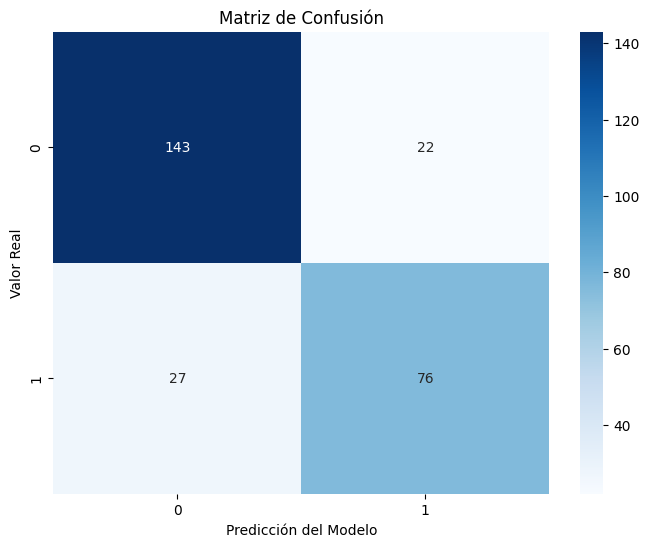

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()